# Telco Customer Churn Prediction

**TKH Student ID / random seed:** 2300114  
**Personalisation:** `df.sample(n=3000, random_state=2300114)` on the 7,043-row Kaggle Telco Customer Churn dataset. All reported metrics come from this personalised 3,000-row subsample.

- Part 1 – Milestone 1: Problem definition, EDA and pre-processing
- Part 2 – Milestone 2: Model implementation, tuning and evaluation

## Part 1 – Milestone 1: EDA and Pre-processing

In [1]:
# Libraries for data handling and plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the original Telco Customer Churn dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Number of rows and columns in the full dataset
df.shape

(7043, 21)

In [4]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Personalise the dataset using my TKH Student ID

STUDENT_ID = 2300114

df_personalized = df.sample(
    n=3000,
    random_state=STUDENT_ID
)

df_personalized.shape

(3000, 21)

In [6]:
# Check for missing values in the personalised sample
df_personalized.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# TotalCharges is stored as text, so check its most common values (one of them is blank)
df_personalized["TotalCharges"].value_counts().head(10)

TotalCharges
19.65    6
20.2     5
69.65    4
19.9     4
20.05    4
         4
19.95    3
85.5     3
20.25    3
74.6     3
Name: count, dtype: int64

In [8]:
# Show the rows where TotalCharges is blank (they all have zero tenure)
df_personalized[df_personalized["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [9]:
# Convert TotalCharges to numbers: blanks become NaN, then 0 because these customers have no accumulated charges
df_personalized["TotalCharges"] = pd.to_numeric(
    df_personalized["TotalCharges"],
    errors="coerce"
)

df_personalized["TotalCharges"] = df_personalized["TotalCharges"].fillna(0)

df_personalized["TotalCharges"].dtype

dtype('float64')

In [10]:
# Confirm that no missing values remain
df_personalized.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
# Count duplicate rows
df_personalized.duplicated().sum()

np.int64(0)

In [12]:
# Confirm that TotalCharges is now numeric
df_personalized.info()

<class 'pandas.DataFrame'>
Index: 3000 entries, 3278 to 2816
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        3000 non-null   str    
 1   gender            3000 non-null   str    
 2   SeniorCitizen     3000 non-null   int64  
 3   Partner           3000 non-null   str    
 4   Dependents        3000 non-null   str    
 5   tenure            3000 non-null   int64  
 6   PhoneService      3000 non-null   str    
 7   MultipleLines     3000 non-null   str    
 8   InternetService   3000 non-null   str    
 9   OnlineSecurity    3000 non-null   str    
 10  OnlineBackup      3000 non-null   str    
 11  DeviceProtection  3000 non-null   str    
 12  TechSupport       3000 non-null   str    
 13  StreamingTV       3000 non-null   str    
 14  StreamingMovies   3000 non-null   str    
 15  Contract          3000 non-null   str    
 16  PaperlessBilling  3000 non-null   str    
 17  PaymentM

In [13]:
# Number of customers in each churn class
df_personalized["Churn"].value_counts()

Churn
No     2212
Yes     788
Name: count, dtype: int64

In [14]:
# Percentage of customers in each churn class
df_personalized["Churn"].value_counts(normalize=True) * 100

Churn
No     73.733333
Yes    26.266667
Name: proportion, dtype: float64

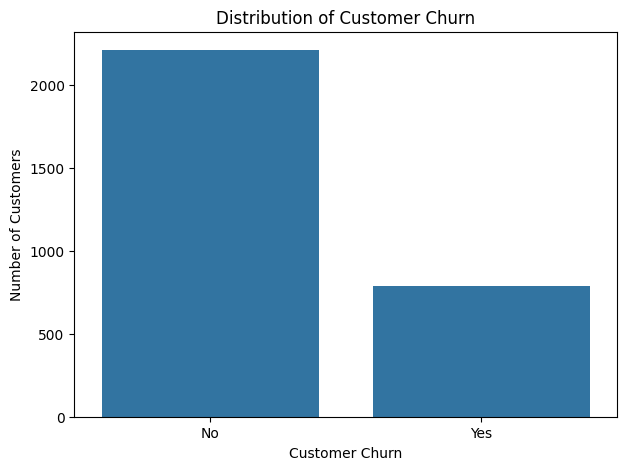

In [15]:
# Bar chart of the two churn classes
plt.figure(figsize=(7, 5))

sns.countplot(data=df_personalized, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

Churn Distribution:

The personalized dataset contains 3,000 customers. out of these, 2,212 customers (73.73%) stayed with the company, while 788 customers (26.27%) left. This shows that the dataset has an imbalance between the two classes, with a greater number of customers staying than leaving.


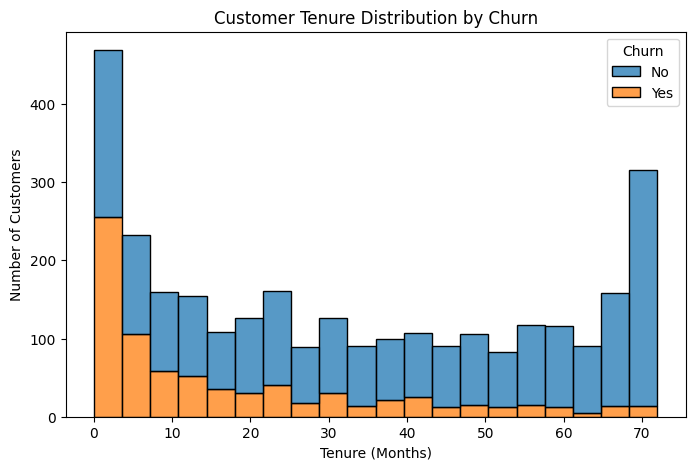

In [16]:
# Tenure distribution, split by churn status
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_personalized,
    x="tenure",
    hue="Churn",
    bins=20,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

Customer Tenure Analysis:

The histogram shows the distribution of customer tenure based on churn status. Customers with shorter tenure appear more frequently among those who left the company, while many long-term customers stayed. This suggests that tenure could be an important feature for predicting customer churn.

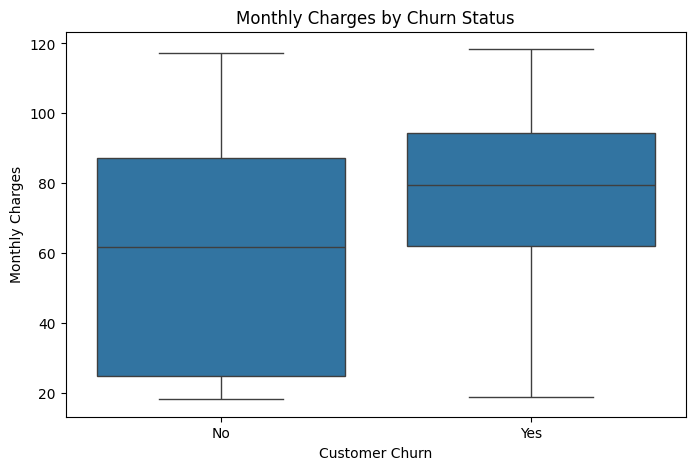

In [17]:
# Compare monthly charges of customers who stayed and customers who left
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_personalized,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [18]:
# Summary statistics of monthly charges for each churn class
df_personalized.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,2212.0,60.331442,31.244625,18.25,24.8375,61.700,87.10,117.15
Yes,788.0,75.297208,23.597371,19.00,61.9500,79.625,94.25,118.35


Monthly Charges Analysis:

The analysis shows that customers who left the company had higher average monthly charges (75.30) than customers who stayed (60.33). The median monthly charge was also higher among customers who churned. This suggests that monthly charges may be a useful feature for predicting customer churn, although the relationship does not necessarily mean that higher charges cause customers to leave.

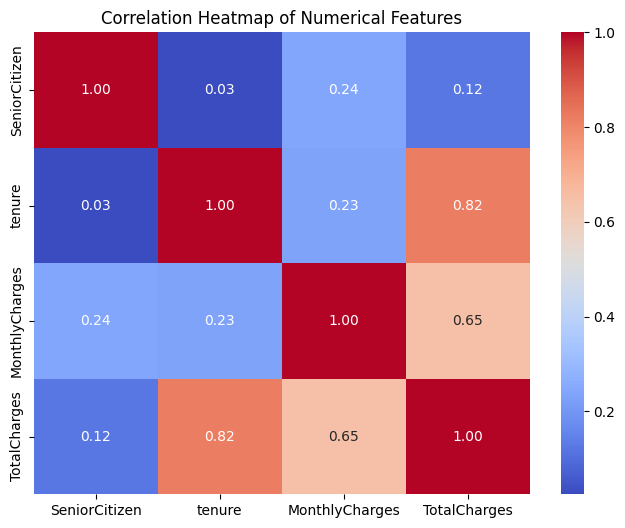

In [19]:
# Correlation between the numerical features
numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation_matrix = df_personalized[numerical_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Correlation Analysis:

The correlation heatmap shows a strong positive relationship between tenure and TotalCharges, with a correlation coefficient near 0.82. This suggests that customers with longer tenure generally accumulate higher total charges. MonthlyCharges and TotalCharges also show a positive relationship of about 0.65. In comparison, the relationships between SeniorCitizen and the other numerical features are relatively weak.

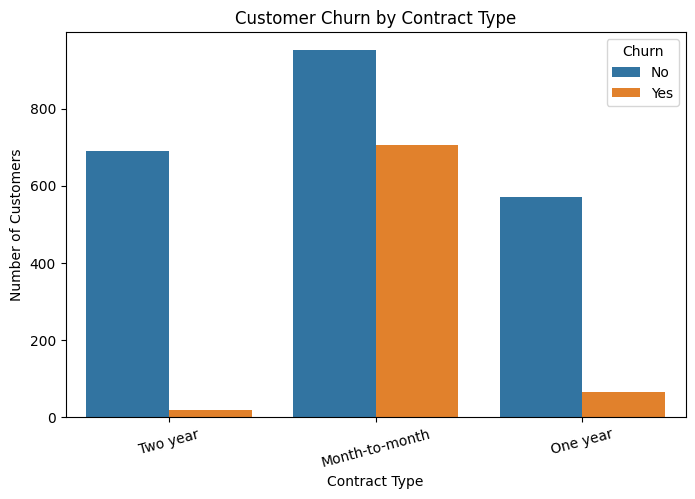

In [20]:
# Churn counts for each contract type
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_personalized,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

Contract Type Analysis:

The graph shows that customers with month-to-month contracts have the highest number of customers who left the company. In comparison, customers with one-year and two-year contracts have fewer cases of churn. This suggests that customers with shorter-term contracts might be more likely to leave than customers with longer-term contracts. Contract type could therefore be an important feature for predicting customer churn.

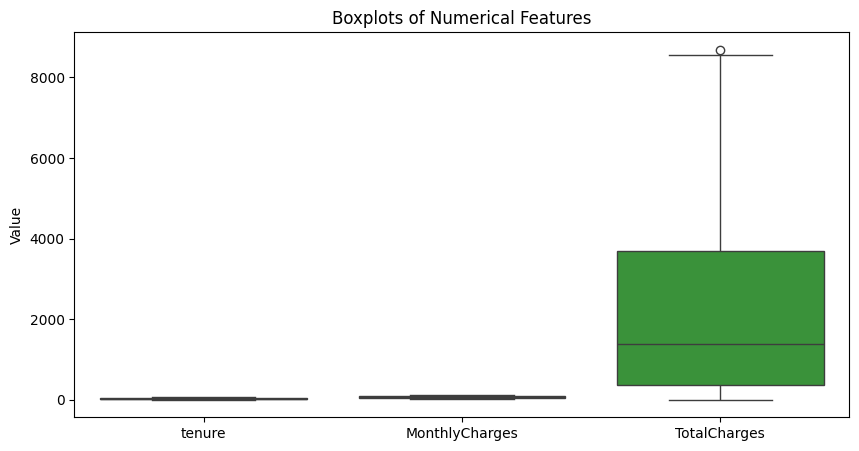

In [21]:
# Boxplots to inspect possible outliers in the numerical features
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_personalized[["tenure", "MonthlyCharges", "TotalCharges"]]
)

plt.title("Boxplots of Numerical Features")
plt.ylabel("Value")
plt.show()

In [22]:
# Count outliers in each numerical feature using the IQR rule
outlier_rows = []
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1 = df_personalized[col].quantile(0.25)
    q3 = df_personalized[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    is_outlier = (df_personalized[col] < lower) | (df_personalized[col] > upper)
    outlier_rows.append({"Feature": col, "Lower bound": lower, "Upper bound": upper,
                         "Max value": df_personalized[col].max(), "Outliers": is_outlier.sum()})

pd.DataFrame(outlier_rows).round(2)

,Feature,Lower bound,Upper bound,Max value,Outliers
0,tenure,-62.50,125.50,72.00,0
1,MonthlyCharges,-47.73,172.08,118.35,0
2,TotalCharges,-4613.92,8681.43,8684.80,1


Outlier Analysis:

Using the IQR rule (values more than 1.5 × IQR outside the quartiles), tenure and MonthlyCharges have no outliers. TotalCharges has one, a value of 8,684.80 that is only just above the upper bound of 8,681.43. This is a genuine long-term, high-paying customer rather than an error, so it was kept.

In [23]:
# Remove customerID because it is an identifier, not a predictive feature
df_personalized = df_personalized.drop(columns=["customerID"])

df_personalized.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3278,Female,0,Yes,Yes,65,Yes,Yes,DSL,No,Yes,No,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),79.40,5071.90,No
4433,Female,0,No,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.65,302.35,No
2314,Female,0,Yes,Yes,72,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),93.25,6688.95,No
2566,Female,0,Yes,Yes,65,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),91.55,5963.95,No
7016,Female,0,No,No,1,Yes,No,DSL,No,Yes,No,No,No,No,Month-to-month,No,Electronic check,49.95,49.95,No


In [24]:
# Check the columns after removing customerID
df_personalized.info()

<class 'pandas.DataFrame'>
Index: 3000 entries, 3278 to 2816
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            3000 non-null   str    
 1   SeniorCitizen     3000 non-null   int64  
 2   Partner           3000 non-null   str    
 3   Dependents        3000 non-null   str    
 4   tenure            3000 non-null   int64  
 5   PhoneService      3000 non-null   str    
 6   MultipleLines     3000 non-null   str    
 7   InternetService   3000 non-null   str    
 8   OnlineSecurity    3000 non-null   str    
 9   OnlineBackup      3000 non-null   str    
 10  DeviceProtection  3000 non-null   str    
 11  TechSupport       3000 non-null   str    
 12  StreamingTV       3000 non-null   str    
 13  StreamingMovies   3000 non-null   str    
 14  Contract          3000 non-null   str    
 15  PaperlessBilling  3000 non-null   str    
 16  PaymentMethod     3000 non-null   str    
 17  MonthlyC

In [25]:
# List the remaining categorical (text) columns
categorical_cols = df_personalized.select_dtypes(
    include="object"
).columns

print(categorical_cols)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')


In [26]:
# Separate the input features (X) from the target (y)
X = df_personalized.drop(columns=["Churn"])
y = df_personalized["Churn"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (3000, 19)
Target shape: (3000,)


In [27]:
# One-hot encode the categorical features; drop_first removes one redundant column per feature
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Original input shape:", X.shape)
print("Encoded input shape:", X_encoded.shape)

X_encoded.head()

Original input shape: (3000, 19)
Encoded input shape: (3000, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3278,0,65,79.40,5071.90,0,1,1,1,0,1,...,0,1,0,1,0,1,1,0,0,0
4433,0,4,75.65,302.35,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0
2314,0,72,93.25,6688.95,0,1,1,1,0,1,...,0,1,0,1,0,1,1,0,0,0
2566,0,65,91.55,5963.95,0,1,1,1,0,1,...,0,1,0,1,0,1,0,0,0,0
7016,0,1,49.95,49.95,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0


In [28]:
# Standardise the numerical columns to mean 0 and standard deviation 1
from sklearn.preprocessing import StandardScaler

numerical_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

scaler = StandardScaler()

X_scaled = X_encoded.copy()

X_scaled[numerical_cols] = scaler.fit_transform(
    X_scaled[numerical_cols]
)

X_scaled.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3278,-0.444528,1.338691,0.502099,1.263554,0,1,1,1,0,1,...,0,1,0,1,0,1,1,0,0,0
4433,-0.444528,-1.143959,0.377715,-0.861474,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0
2314,-0.444528,1.623585,0.961492,1.984015,0,1,1,1,0,1,...,0,1,0,1,0,1,1,0,0,0
2566,-0.444528,1.338691,0.905104,1.660998,0,1,1,1,0,1,...,0,1,0,1,0,1,0,0,0,0
7016,-0.444528,-1.266056,-0.474731,-0.973928,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0


In [29]:
# Check the scaling: means should be about 0 and standard deviations about 1
X_scaled[numerical_cols].describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,3000.00,3000.00,3000.00,3000.00
mean,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.44,-1.31,-1.53,-1.00
25%,-0.44,-0.98,-0.98,-0.83
50%,-0.44,-0.15,0.20,-0.38
75%,-0.44,0.93,0.84,0.65
max,2.25,1.62,1.79,2.87


In [30]:
# Save the prepared dataset together with the original Churn target
prepared_data = X_scaled.copy()
prepared_data["Churn"] = y

prepared_data.to_csv(
    "telco_churn_prepared.csv",
    index=False
)

print("Prepared dataset saved successfully!")
print("Dataset shape:", prepared_data.shape)

Prepared dataset saved successfully!
Dataset shape: (3000, 31)


## Part 2 – Milestone 2: Model Implementation & Evaluation

**Avoiding data leakage.** In Milestone 1 the `StandardScaler` was fitted on all 3,000 rows. If that file were used for modelling, the test set would have influenced the scaling. In this part the cleaned data (`df_personalized`, after the `TotalCharges` fix and dropping `customerID`) is split first, and all encoding, scaling and clustering is placed inside a scikit-learn `Pipeline`. This way, each cross-validation fold and the final model are fitted using only their own training data.

In [31]:
import warnings
warnings.filterwarnings("ignore")

import os
from scipy.stats import loguniform, randint
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV, RandomizedSearchCV)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve)

os.makedirs("figures", exist_ok=True)

### 2.1 Train/test split
The target is converted to 1 = churn and 0 = stay. 20% of the personalised data is held out as a test set. The split is stratified, so both sets keep the 26% churn rate, and it uses the student ID as the seed. The test set is used only once, for the final evaluation.

In [32]:
X_m2 = df_personalized.drop(columns=["Churn"])
y_m2 = (df_personalized["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_m2, y_m2, test_size=0.2, stratify=y_m2, random_state=STUDENT_ID
)

print("Training set:", X_train.shape, "churn rate = %.3f" % y_train.mean())
print("Test set:    ", X_test.shape, "churn rate = %.3f" % y_test.mean())

Training set: (2400, 19) churn rate = 0.263
Test set:     (600, 19) churn rate = 0.263


In [33]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = X_m2.select_dtypes(include="object").columns.tolist()

print("Numerical (scaled):", num_cols)
print("Binary (passed through): ['SeniorCitizen']")
print("Categorical (one-hot):", len(cat_cols), "columns")

Numerical (scaled): ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary (passed through): ['SeniorCitizen']
Categorical (one-hot): 15 columns


### 2.2 Unsupervised learning: K-Means customer segmentation
K-Means is used for **feature engineering**. Customers are grouped by their standardised `tenure`, `MonthlyCharges` and `TotalCharges`. Each customer's segment is then added as an extra categorical feature. The number of clusters is chosen using the elbow method and the silhouette score on the training set only.

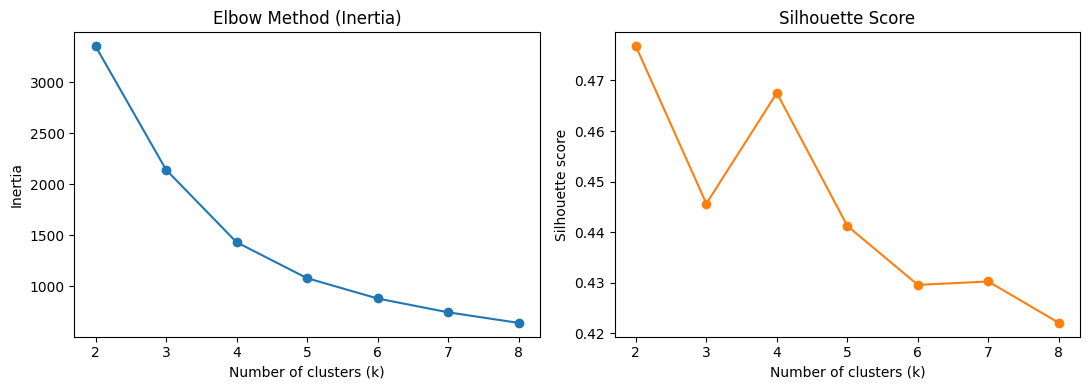

,k,inertia,silhouette
0,2,3354.399,0.477
1,3,2141.703,0.446
2,4,1430.304,0.468
3,5,1077.760,0.441
4,6,878.371,0.430
5,7,742.742,0.430
6,8,638.809,0.422


In [34]:
seg_scaler = StandardScaler()
train_num_scaled = seg_scaler.fit_transform(X_train[num_cols])

k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=STUDENT_ID).fit(train_num_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(train_num_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="tab:orange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig("figures/kmeans_k_selection.png", dpi=150)
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes}).round(3)

**Choosing k.** k = 2 has the highest silhouette score (0.477), but two clusters mostly separate customers by tenure, and the models already have that feature. k = 4 has almost the same silhouette score (0.468), and the elbow plot shows that inertia stops falling steeply after k = 4. Four clusters also split customers by both tenure and price, which makes them easier to interpret, so **k = 4** is used.

In [35]:
K_SEG = 4

kmeans = KMeans(n_clusters=K_SEG, n_init=10, random_state=STUDENT_ID).fit(train_num_scaled)
segments = X_train[num_cols].copy()
segments["Segment"] = kmeans.labels_
segments["Churn"] = y_train.values

profile = segments.groupby("Segment").agg(
    customers=("Churn", "size"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    avg_total=("TotalCharges", "mean"),
    churn_rate=("Churn", "mean"),
).round(2)
profile

,customers,avg_tenure,avg_monthly,avg_total,churn_rate
Segment,,,,,
0,782,15.55,80.82,1263.89,0.49
1,598,10.09,32.23,302.12,0.23
2,388,53.61,34.10,1782.78,0.04
3,632,59.55,92.68,5511.59,0.15


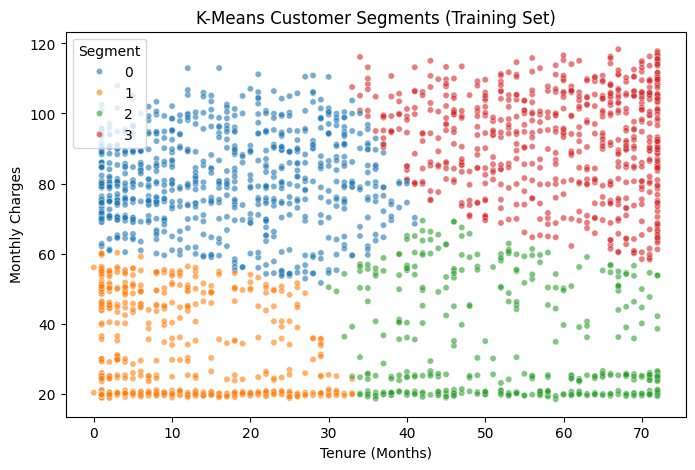

In [36]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=segments, x="tenure", y="MonthlyCharges", hue="Segment",
                palette="tab10", alpha=0.6, s=20)
plt.title("K-Means Customer Segments (Training Set)")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.savefig("figures/kmeans_segments.png", dpi=150)
plt.show()

**Segment interpretation.** The four segments have very different churn rates:
- **S0 – new, high-paying** (≈16 months, ≈£81/month): **49% churn**, which is the highest-risk group.
- **S1 – new, low-paying** (≈10 months, ≈£32/month): 23% churn.
- **S3 – loyal, premium** (≈60 months, ≈£93/month): 15% churn.
- **S2 – loyal, low-paying** (≈54 months, ≈£34/month): only 4% churn.

This supports the Milestone 1 EDA: short tenure combined with high monthly charges is the riskiest profile. (The segment numbers come from K-Means and can change if the seed changes.)

### 2.3 Building the pipeline
`KMeansSegmenter` is a custom transformer that adds the `Segment` column to the data. Because it is part of the pipeline, K-Means is re-fitted inside every training fold. Setting `n_clusters=0` turns the segment feature off. This lets cross-validation and the hyperparameter search test whether the unsupervised feature actually improves the models.

In [37]:
class KMeansSegmenter(BaseEstimator, TransformerMixin):
    """Adds a 'Segment' column from K-Means fitted on the scaled numerical features.
    n_clusters=0 switches the feature off (constant segment)."""

    def __init__(self, n_clusters=4, cols=("tenure", "MonthlyCharges", "TotalCharges"),
                 random_state=STUDENT_ID):
        self.n_clusters = n_clusters
        self.cols = cols
        self.random_state = random_state

    def fit(self, X, y=None):
        if self.n_clusters:
            self.scaler_ = StandardScaler().fit(X[list(self.cols)])
            self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=10,
                                  random_state=self.random_state)
            self.kmeans_.fit(self.scaler_.transform(X[list(self.cols)]))
        return self

    def transform(self, X):
        X = X.copy()
        if self.n_clusters:
            labels = self.kmeans_.predict(self.scaler_.transform(X[list(self.cols)]))
            X["Segment"] = ["S" + str(label) for label in labels]
        else:
            X["Segment"] = "none"
        return X


def build_pipeline(model, n_clusters=0):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols + ["Segment"]),
    ], remainder="passthrough")   # SeniorCitizen is already 0/1

    return Pipeline([
        ("segment", KMeansSegmenter(n_clusters=n_clusters)),
        ("prep", preprocessor),
        ("model", model),
    ])

build_pipeline(LogisticRegression(), K_SEG)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('segment', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,n_clusters,4
,cols,"('tenure', ...)"
,random_state,2300114
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold

### 2.4 Baseline models with 5-fold stratified cross-validation
Three supervised algorithms are compared against a majority-class dummy baseline:
- **Logistic Regression**: a linear and easily interpretable model, used as a strong baseline.
- **Random Forest**: a bagged tree ensemble that captures non-linear patterns and interactions.
- **Histogram Gradient Boosting**: a boosted tree ensemble that is often the strongest model on tabular data.

Only 26% of customers churn, so `class_weight="balanced"` is used. This gives more weight to errors on churners during training. Accuracy alone would be misleading here, because the dummy model reaches about 74% by always predicting "stay". **F1 for the churn class** is therefore the main metric, and recall, precision and ROC-AUC are also reported. Each model is tested with and without the K-Means segment feature.

In [38]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=STUDENT_ID)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

base_models = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=STUDENT_ID, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced",
                                                        random_state=STUDENT_ID),
}

rows = []
for name, model in base_models.items():
    for k in [0, K_SEG]:
        if name.startswith("Dummy") and k:
            continue
        res = cross_validate(build_pipeline(model, k), X_train, y_train,
                             cv=cv, scoring=scoring, n_jobs=-1)
        row = {"Model": name, "K-Means segment": "Yes" if k else "No"}
        for m in scoring:
            row[m] = res["test_" + m].mean()
        row["f1_std"] = res["test_f1"].std()
        rows.append(row)

baseline_results = pd.DataFrame(rows).round(3)
baseline_results

,Model,K-Means segment,accuracy,precision,recall,f1,roc_auc,f1_std
0,Dummy (majority),No,0.738,0.000,0.000,0.000,0.500,0.000
1,Logistic Regression,No,0.753,0.519,0.803,0.630,0.849,0.009
2,Logistic Regression,Yes,0.754,0.521,0.805,0.632,0.849,0.009
3,Random Forest,No,0.799,0.663,0.479,0.556,0.829,0.029
4,Random Forest,Yes,0.798,0.657,0.481,0.555,0.828,0.035
5,Gradient Boosting,No,0.768,0.548,0.662,0.599,0.821,0.039
6,Gradient Boosting,Yes,0.767,0.547,0.660,0.598,0.818,0.038


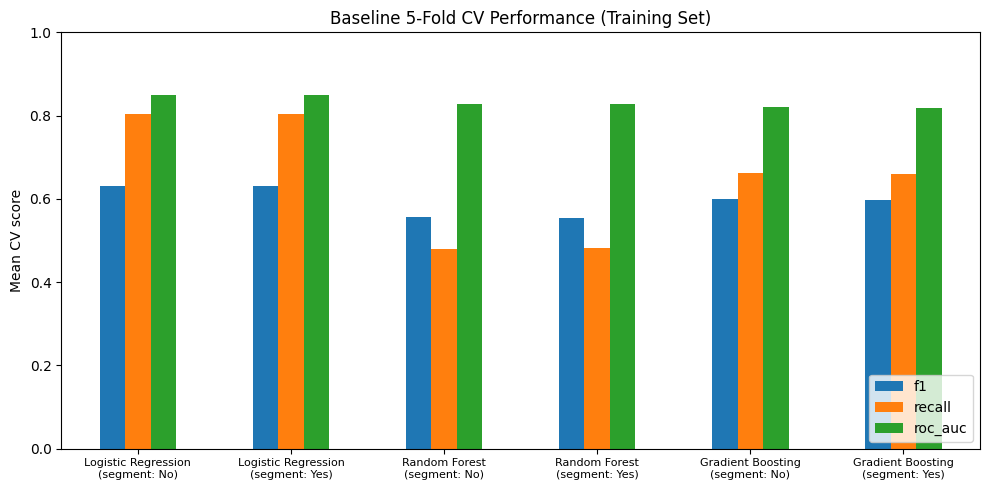

In [39]:
plot_df = baseline_results[baseline_results["Model"] != "Dummy (majority)"].copy()
plot_df["Setting"] = plot_df["Model"] + "\n(segment: " + plot_df["K-Means segment"] + ")"

fig, ax = plt.subplots(figsize=(10, 5))
plot_df.set_index("Setting")[["f1", "recall", "roc_auc"]].plot(kind="bar", ax=ax)
ax.set_title("Baseline 5-Fold CV Performance (Training Set)")
ax.set_ylabel("Mean CV score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
plt.xticks(rotation=0, fontsize=8)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/baseline_cv.png", dpi=150)
plt.show()

**Baseline findings.**
- The dummy model reaches 73.8% accuracy but an F1 of 0. This confirms that accuracy is not a suitable main metric for this problem.
- With default settings, **Logistic Regression** is the best model (F1 0.630, ROC-AUC 0.849), and its results are the most stable across folds (F1 std 0.009).
- The default **Random Forest** has the highest accuracy (0.799) but the lowest recall (0.479). Its fully grown trees fit the training data closely and produce very confident probabilities. Because of this, `class_weight` does not shift many predictions above 0.5, and many churners are missed.
- Adding the K-Means segment changes the scores by at most ±0.003, so the effect is negligible.

### 2.5 Hyperparameter tuning
Each model is tuned with 5-fold stratified CV on the training set, using F1 as the selection metric (`refit="f1"`). The K-Means segment feature (`segment__n_clusters`) is included in every search. This lets the search decide whether the feature should be used.
- Logistic Regression and Random Forest: **Grid Search**, because their search spaces are small.
- Gradient Boosting: **Randomized Search** with 40 samples, because it has many continuous hyperparameters.

In [40]:
lr_search = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=2000)),
    param_grid={
        "segment__n_clusters": [0, K_SEG],
        "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=-1,
)
lr_search.fit(X_train, y_train)
print("Logistic Regression best params:", lr_search.best_params_)
print("Best CV F1: %.3f" % lr_search.best_score_)

Logistic Regression best params: {'model__C': 100, 'model__class_weight': 'balanced', 'segment__n_clusters': 4}
Best CV F1: 0.635


In [41]:
rf_search = GridSearchCV(
    build_pipeline(RandomForestClassifier(class_weight="balanced", random_state=STUDENT_ID, n_jobs=-1)),
    param_grid={
        "segment__n_clusters": [0, K_SEG],
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 6, 10],
        "model__min_samples_leaf": [1, 5, 10],
        "model__max_features": ["sqrt", 0.5],
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
print("Best CV F1: %.3f" % rf_search.best_score_)

Random Forest best params: {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__n_estimators': 200, 'segment__n_clusters': 0}
Best CV F1: 0.649


In [42]:
gb_search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=STUDENT_ID)),
    param_distributions={
        "segment__n_clusters": [0, K_SEG],
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__max_iter": randint(50, 400),
        "model__max_depth": [None, 2, 3, 5],
        "model__max_leaf_nodes": randint(4, 40),
        "model__min_samples_leaf": randint(10, 100),
        "model__l2_regularization": loguniform(1e-3, 10),
    },
    n_iter=40, scoring=scoring, refit="f1", cv=cv, n_jobs=-1, random_state=STUDENT_ID,
)
gb_search.fit(X_train, y_train)
print("Gradient Boosting best params:", gb_search.best_params_)
print("Best CV F1: %.3f" % gb_search.best_score_)

Gradient Boosting best params: {'model__l2_regularization': np.float64(0.2047275329314355), 'model__learning_rate': np.float64(0.04651762956307737), 'model__max_depth': 2, 'model__max_iter': 279, 'model__max_leaf_nodes': 37, 'model__min_samples_leaf': 49, 'segment__n_clusters': 4}
Best CV F1: 0.632


In [43]:
searches = {"Logistic Regression": lr_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}

rows = []
for name, search in searches.items():
    i = search.best_index_
    before = baseline_results[(baseline_results["Model"] == name) &
                              (baseline_results["K-Means segment"] == "No")].iloc[0]
    rows.append({
        "Model": name,
        "Segment k": search.best_params_["segment__n_clusters"],
        "Baseline CV F1": before["f1"],
        "Tuned CV F1": search.cv_results_["mean_test_f1"][i],
        "Tuned CV F1 std": search.cv_results_["std_test_f1"][i],
        "Tuned CV Recall": search.cv_results_["mean_test_recall"][i],
        "Tuned CV Precision": search.cv_results_["mean_test_precision"][i],
        "Tuned CV ROC-AUC": search.cv_results_["mean_test_roc_auc"][i],
    })
tuning_results = pd.DataFrame(rows).round(3)
tuning_results

,Model,Segment k,Baseline CV F1,Tuned CV F1,Tuned CV F1 std,Tuned CV Recall,Tuned CV Precision,Tuned CV ROC-AUC
0,Logistic Regression,4,0.630,0.635,0.010,0.808,0.524,0.848
1,Random Forest,0,0.556,0.649,0.024,0.767,0.563,0.847
2,Gradient Boosting,4,0.599,0.632,0.011,0.790,0.527,0.845


In [44]:
# Effect of the K-Means segment feature: best CV F1 with and without it, per model
rows = []
for name, search in searches.items():
    res = pd.DataFrame(search.cv_results_)
    best_by_k = res.groupby("param_segment__n_clusters")["mean_test_f1"].max()
    rows.append({"Model": name, "Best F1 without segment": best_by_k.loc[0],
                 "Best F1 with segment": best_by_k.loc[K_SEG]})
pd.DataFrame(rows).round(3)

,Model,Best F1 without segment,Best F1 with segment
0,Logistic Regression,0.633,0.635
1,Random Forest,0.649,0.645
2,Gradient Boosting,0.632,0.632


**Tuning findings.**
- **Random Forest** improves the most (F1 0.556 → 0.649). Limiting `max_depth` to 10 and setting `min_samples_leaf` to 10 regularises the trees and makes the probabilities less extreme. Together with the balanced class weights, this raises recall from 0.48 to 0.77.
- **Gradient Boosting** improves from 0.599 to 0.632 by using shallow trees (`max_depth=2`) and a low learning rate. The overfitting check below confirms that the default setting was overfitting the 2,400 training rows.
- **Logistic Regression** hardly changes (0.630 → 0.635), so its default setting was already close to the best one.
- **K-Means segment:** the search selected it for LR and GB, but the gain is at most 0.002 F1, which is far smaller than the fold-to-fold standard deviation of 0.01–0.02. The segments are created only from tenure and charges, which the models already use directly. They help interpretation, but they do not add new predictive information.
- After tuning, all three models are within 0.02 F1 of each other.

### Overfitting check
Training F1 is compared with cross-validated F1. A large gap means a model has fitted the training data much better than unseen data, which is overfitting. CV F1 is used rather than test F1, so the test set stays unused until the final evaluation.

In [45]:
# Overfitting check: compare training F1 with cross-validated F1 for each model
rows = []
for name in searches:
    default_model = build_pipeline(base_models[name]).fit(X_train, y_train)
    default_cv = baseline_results[(baseline_results["Model"] == name) &
                                  (baseline_results["K-Means segment"] == "No")]["f1"].iloc[0]
    tuned_cv = tuning_results[tuning_results["Model"] == name]["Tuned CV F1"].iloc[0]

    for version, model, cv_f1 in [("Default", default_model, default_cv),
                                  ("Tuned", searches[name].best_estimator_, tuned_cv)]:
        train_f1 = f1_score(y_train, model.predict(X_train))
        rows.append({"Model": name, "Version": version, "Train F1": train_f1,
                     "CV F1": cv_f1, "Gap": train_f1 - cv_f1})

overfitting_check = pd.DataFrame(rows).round(3)
overfitting_check

,Model,Version,Train F1,CV F1,Gap
0,Logistic Regression,Default,0.642,0.630,0.012
1,Logistic Regression,Tuned,0.641,0.635,0.006
2,Random Forest,Default,0.999,0.556,0.443
3,Random Forest,Tuned,0.702,0.649,0.053
4,Gradient Boosting,Default,0.864,0.599,0.265
5,Gradient Boosting,Tuned,0.660,0.632,0.028


**Overfitting findings.**
- The default **Random Forest** clearly overfits: its training F1 is 0.999 but its CV F1 is only 0.556 (gap 0.443). Tuning reduces the gap to 0.053.
- The default **Gradient Boosting** also overfits (gap 0.265). Tuning reduces the gap to 0.028.
- **Logistic Regression** does not overfit (gap 0.012 by default and 0.006 after tuning), because it is a simpler linear model.

This confirms that the main benefit of tuning the tree ensembles was regularisation: their F1 on unseen folds rose even though their training F1 fell.

### 2.6 Final evaluation on the held-out test set
Each tuned pipeline has already been refitted on the full training set by the search. It is now evaluated once on the 600 test customers that were not used at any earlier stage.

In [46]:
tuned_models = {name: s.best_estimator_ for name, s in searches.items()}

rows = []
for name, model in tuned_models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
test_results = pd.DataFrame(rows).round(3)
test_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752,0.519,0.791,0.627,0.865
1,Random Forest,0.778,0.557,0.778,0.649,0.861
2,Gradient Boosting,0.755,0.523,0.791,0.630,0.859


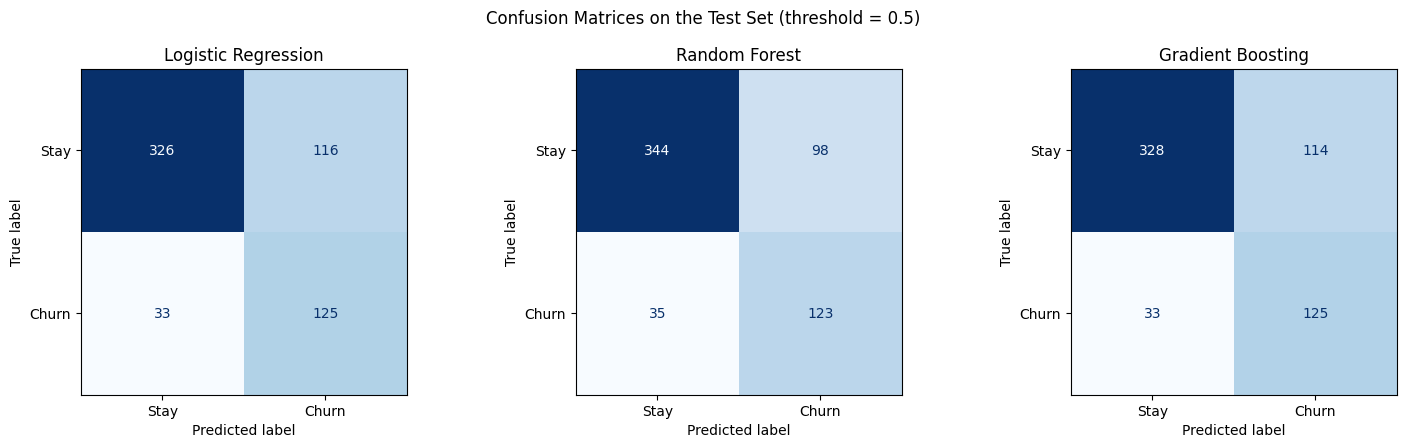

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues",
                                          display_labels=["Stay", "Churn"], colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion Matrices on the Test Set (threshold = 0.5)")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()

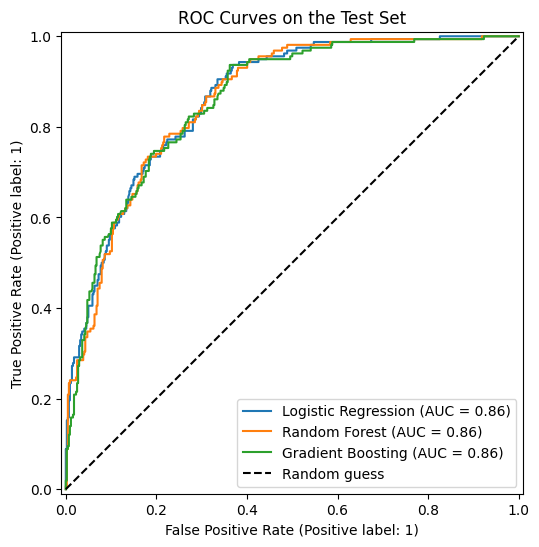

In [48]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves on the Test Set")
ax.legend(loc="lower right")
plt.savefig("figures/roc_curves.png", dpi=150)
plt.show()

In [49]:
for name, model in tuned_models.items():
    print("=" * 20, name, "=" * 20)
    print(classification_report(y_test, model.predict(X_test), target_names=["Stay", "Churn"]))

==================== Logistic Regression ====================
              precision    recall  f1-score   support

        Stay       0.91      0.74      0.81       442
       Churn       0.52      0.79      0.63       158

    accuracy                           0.75       600
   macro avg       0.71      0.76      0.72       600
weighted avg       0.81      0.75      0.76       600

==================== Random Forest ====================
              precision    recall  f1-score   support

        Stay       0.91      0.78      0.84       442
       Churn       0.56      0.78      0.65       158

    accuracy                           0.78       600
   macro avg       0.73      0.78      0.74       600
weighted avg       0.82      0.78      0.79       600

==================== Gradient Boosting ====================
              precision    recall  f1-score   support

        Stay       0.91      0.74      0.82       442
       Churn       0.52      0.79      0.63       158

    

**Test-set findings.**
- The test scores are close to the CV estimates, for example Random Forest F1 0.649 on both. This means the models were not overfitted to the CV folds.
- **Random Forest** has the best F1 (0.649) and accuracy (0.778). It correctly identifies 123 of the 158 churners (recall 0.78) and wrongly flags 98 customers who stayed.
- **Logistic Regression** has the highest ROC-AUC (0.865), so it ranks customers by risk slightly better. However, it produces more false alarms at the 0.5 threshold.
- For a retention campaign, missing a churner (FN) usually costs more than sending an offer to a loyal customer (FP). The high recall from class weighting is therefore a reasonable trade-off.

### 2.7 Decision threshold selection
By default, a customer is labelled as churn when the predicted probability is at least 0.5. The best model is chosen by **CV F1**, not by test score, so the test set does not influence model selection. Its decision threshold is then tuned using out-of-fold predictions on the training set. The threshold that gives the highest F1 is applied once to the test set.

Best model by CV F1: Random Forest


Threshold with the highest out-of-fold F1: 0.503 (F1 = 0.650)


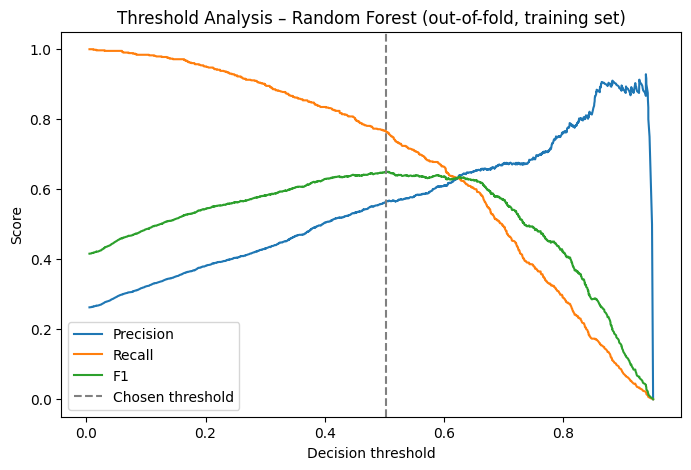

In [50]:
best_name = tuning_results.sort_values("Tuned CV F1", ascending=False)["Model"].iloc[0]
best_model = tuned_models[best_name]
print("Best model by CV F1:", best_name)

oof_proba = cross_val_predict(searches[best_name].best_estimator_, X_train, y_train,
                              cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_values = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = thr[np.argmax(f1_values)]
print("Threshold with the highest out-of-fold F1: %.3f (F1 = %.3f)" % (best_threshold, f1_values.max()))

plt.figure(figsize=(8, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1_values, label="F1")
plt.axvline(best_threshold, color="grey", linestyle="--", label="Chosen threshold")
plt.title(f"Threshold Analysis – {best_name} (out-of-fold, training set)")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.legend()
plt.savefig("figures/threshold_analysis.png", dpi=150)
plt.show()

In [51]:
test_proba = best_model.predict_proba(X_test)[:, 1]
rows = []
for label, t in [("Default (0.50)", 0.5), ("Tuned (%.2f)" % best_threshold, best_threshold)]:
    pred = (test_proba >= t).astype(int)
    rows.append({"Threshold": label,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
pd.DataFrame(rows).round(3)

,Threshold,Accuracy,Precision,Recall,F1
0,Default (0.50),0.778,0.557,0.778,0.649
1,Tuned (0.50),0.780,0.559,0.778,0.651


**Threshold finding.** The F1-optimal threshold is 0.50, which is almost identical to the default, and test F1 only changes from 0.649 to 0.651. The balanced class weights have already moved the decision boundary to a good position. The plot also shows the trade-off a business could choose: a lower threshold finds more churners but produces more false alarms.

### 2.8 Which features drive the predictions?
Permutation importance is computed on the test set for the best model. It measures how much ROC-AUC falls when one original column is randomly shuffled. Because the whole pipeline is used, the results are reported for the original features rather than the one-hot encoded columns.

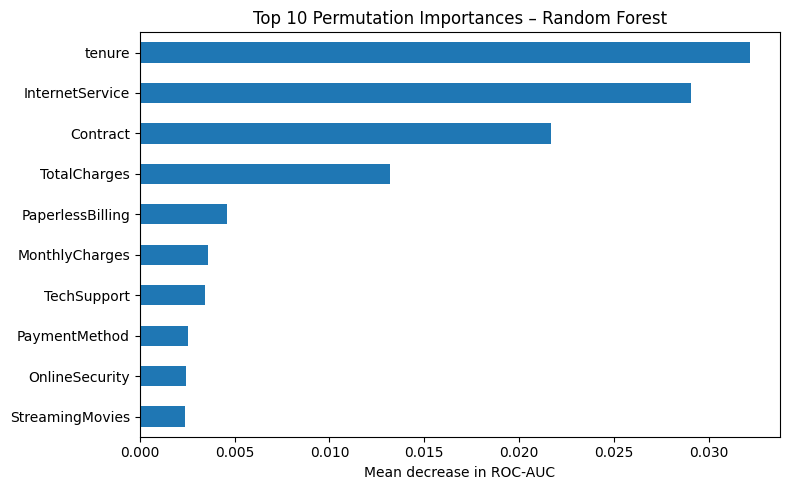

tenure              0.0321
InternetService     0.0291
Contract            0.0217
TotalCharges        0.0132
PaperlessBilling    0.0046
MonthlyCharges      0.0036
TechSupport         0.0035
PaymentMethod       0.0026
OnlineSecurity      0.0025
StreamingMovies     0.0024
dtype: float64

In [52]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=STUDENT_ID, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.head(10)[::-1].plot(kind="barh")
plt.title(f"Top 10 Permutation Importances – {best_name}")
plt.xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", dpi=150)
plt.show()

importance.head(10).round(4)

**Feature importance.** `tenure`, `InternetService` and `Contract` are the most important features, followed by `TotalCharges`. These are the same factors identified in the Milestone 1 EDA: new customers, fibre-optic customers and month-to-month contracts carry the highest churn risk. `gender` and the phone-related features contribute almost nothing.

### 2.9 Summary
| | Logistic Regression | Random Forest | Gradient Boosting |
|---|---|---|---|
| Tuned CV F1 | 0.635 | **0.649** | 0.632 |
| Test F1 | 0.627 | **0.649** | 0.630 |
| Test Recall | 0.791 | 0.778 | 0.791 |
| Test ROC-AUC | **0.865** | 0.861 | 0.859 |

The **tuned Random Forest** is selected as the final model because it has the best F1 in both CV and testing. Logistic Regression is a close, more interpretable alternative and would be a reasonable choice if explainability is the priority. K-Means segmentation produced clear customer groups with different churn rates, but it did not measurably improve the classifiers.